# Create a Landsat Composite

*Section 10 — Case study: ICESat-2 bathymetry, notebook 2 of 5.* Previous: `01_visualise_icesat2`. Next: `03_landsat_composite_bathymetry`.

**You will learn:**
- how to summarise a stack of partially cloud-free images into mean, median, minimum and maximum composites (`rsgispy.imagecalc.stats.calc_multi_img_band_stats`);
- how to create percentile composites (`rsgispy.imagecalc.percentiles.calc_img_band_pxl_percentiles`);
- how to build a "best pixel" composite (max. NDVI over land, medoid over the sea), keeping each output pixel as a single observation, together with a land/water mask and a reference (source image) layer (`rsgispy.imageutils.composite.create_max_ndvi_ndwi_composite`);
- how to name the classes of a thematic image for map legends (`rsgispy.imageutils.colourtable.set_thematic_classes`);
- how to create geometric median (geomedian), per-band median (`create_geomedian_composite`, `create_percentile_composite`) and quality mosaic (`create_quality_mosaic`) composites and compare them side by side (`rsgispy.mapping.layout.create_map_panels`).

**Before you start:** `01_getting_started` (reading and displaying images) and `02_making_maps`.

**Data:** the 11 Landsat 8/9 surface reflectance scenes in `../data/is2_bathy/ls_imgs/` (clouds already masked, no data = -9999).

**Run time:** about 2 minutes (the geomedian composite takes about 30 seconds).

We have 11 input Landsat images which provide partial coverage of the study region. A common solution to this problem is to create some form of composite of those images creating a single image which covers the full region.

In this notebook you will look at a number of options for creating a composite.

# 1. Define Imports

In [1]:
import glob
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy
import rsgispy
import rsgispy.imagecalc.percentiles
import rsgispy.imagecalc.stats
import rsgispy.imageutils.arrays
import rsgispy.imageutils.colourtable
import rsgispy.imageutils.composite
import rsgispy.imageutils.metadata
import rsgispy.imageutils.stats
import rsgispy.mapping.layout as map_layout
import rsgispy.mapping.raster
import rsgispy.tools.files

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

## 1.1 Create output directory

All the outputs of this section are written under its `outputs/` folder. The composites from this notebook go in `outputs/ls_comp` and are used by the next notebook.

In [2]:
out_dir = "outputs/ls_comp"
os.makedirs(out_dir, exist_ok=True)

# 2. Define the input images

Using glob get a list of all the input images (sorted, so the order and therefore the reference image numbers below are the same on every computer).

In [3]:
input_imgs = sorted(glob.glob("../data/is2_bathy/ls_imgs/*.tif"))
for i, input_img in enumerate(input_imgs):
    print(f"{i+1}: {input_img}")

1: ../data/is2_bathy/ls_imgs/lc08_l2sp_006037_20150122_20200910_02_t1_sref_sub_mskd.tif
2: ../data/is2_bathy/ls_imgs/lc08_l2sp_006037_20180623_20200831_02_t1_sref_sub_mskd.tif
3: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20170417_20200904_02_t1_sref_sub_mskd.tif
4: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20170807_20200903_02_t1_sref_sub_mskd.tif
5: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20180522_20200901_02_t1_sref_sub_mskd.tif
6: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20190829_20200826_02_t1_sref_sub_mskd.tif
7: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20210311_20210317_02_t1_sref_sub_mskd.tif
8: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20210615_20210622_02_t1_sref_sub_mskd.tif
9: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20210802_20210811_02_t1_sref_sub_mskd.tif
10: ../data/is2_bathy/ls_imgs/lc08_l2sp_006038_20211021_20211103_02_t1_sref_sub_mskd.tif
11: ../data/is2_bathy/ls_imgs/lc09_l2sp_006038_20220101_20220123_02_t1_sref_sub_mskd.tif


# 3. Visualise the Input Images

It is recommended that you open these images in either TuiView or QGIS or similar to check out the images in detail. Are there bits of cloud missing or other data issues which you might want to sort out before moving on with the processing? **Note, errors in the input image will affect the quality of the outputs**

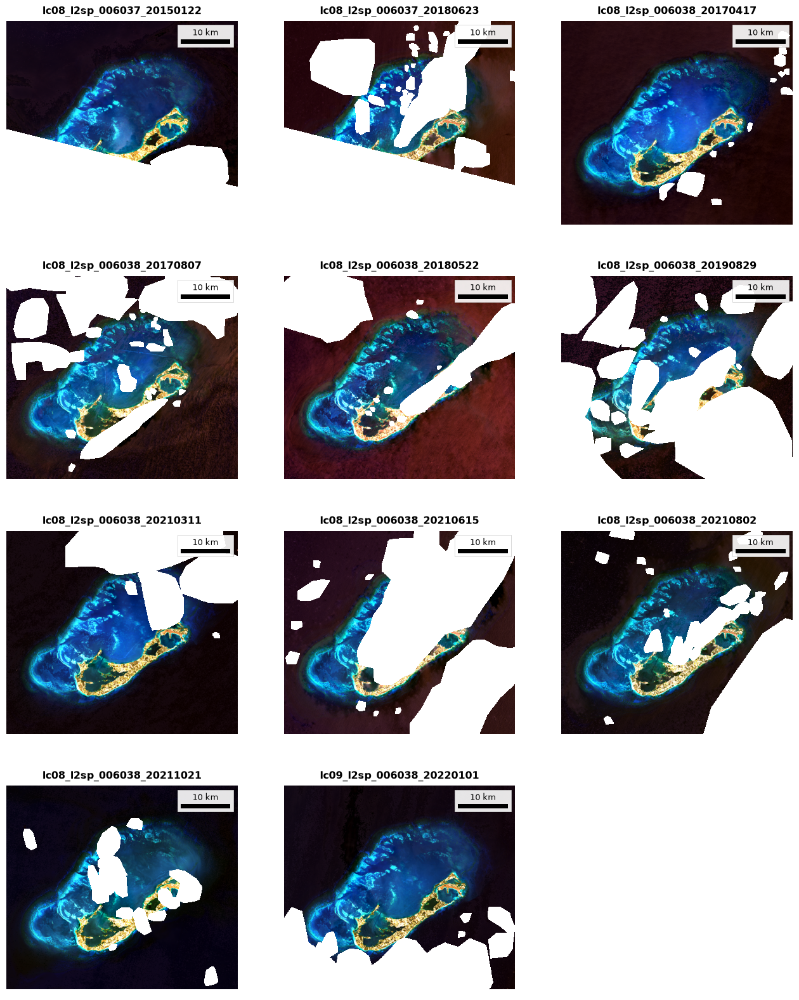

In [4]:
# Create the matplotlib figure - in this case a grid of 4 x 3.
(
    fig,
    ((ax1, ax2, ax3), (ax4, ax5, ax6), (ax7, ax8, ax9), (ax10, ax11, ax12)),
) = plt.subplots(4, 3, figsize=(16, 20), sharey=True, sharex=True)
# Create a list for the 11 axes used for the plot - note we are ignoring ax12 as there are 11 input images.
plot_axes = [ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9, ax10, ax11]

for ax, input_img in zip(plot_axes, input_imgs):
    # Get the first part of the file name to use as the plot title
    basename = rsgispy.tools.files.get_file_basename(input_img, n_comps=4)
    _ = rsgispy.mapping.raster.create_raster_img_map(
        ax,
        input_img,
        img_bands=[4, 3, 2],
        img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
        no_data_val=-9999,
        title_str=basename,
        show_scale_bar=True,
        show_map_axis=False,
    )

ax12.set_axis_off()

What can you see looking at all these images?

 1. They all have bits missing - due to cloud cover.
 2. They all show the same patterns in the water but maybe the contrast between them is a little bit different?

# 4. Create a Mean Composite

One of the simplest things to do is to just take the mean pixel value for each band from all the input images, ignoring the no data values.

However, this means that each band is treated independently which is not ideal. Additionally, means can be easily altered by outliers (e.g., clouds or cloud shadows).

> **Note:** `calc_multi_img_band_stats` ignores the `no_data_val` pixels of the inputs but does not set a no data value on the output image, so we set it with `set_img_no_data_value` and then calculate the image statistics and pyramids with `pop_img_stats`.

In [5]:
mean_comp_img = os.path.join(out_dir, "bermuda_mean_landsat_comp.tif")
rsgispy.imagecalc.stats.calc_multi_img_band_stats(
    input_imgs,
    mean_comp_img,
    rsgispy.SUMTYPE_MEAN,
    use_no_data=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32INT,
    no_data_val=-9999,
)
# Set the no data value on the output and calculate the statistics and pyramids
rsgispy.imageutils.metadata.set_img_no_data_value(mean_comp_img, -9999)
rsgispy.imageutils.stats.pop_img_stats(mean_comp_img, no_data_val=-9999, calc_pyramids=True)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

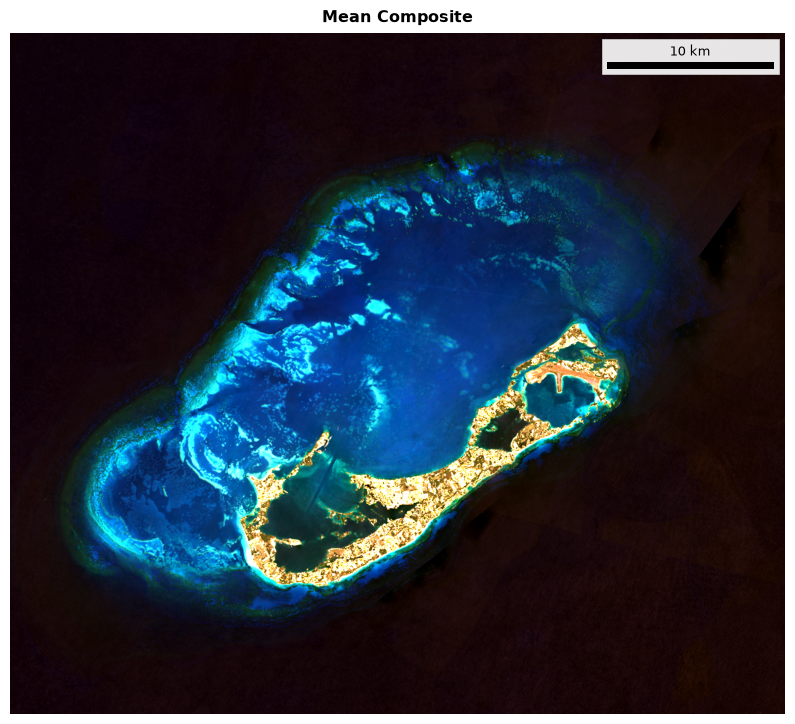

In [6]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    mean_comp_img,
    img_bands=[4, 3, 2],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    no_data_val=-9999,
    title_str="Mean Composite",
    show_scale_bar=True,
    show_map_axis=False,
)

# 5. Create a Median Composite

A better alternative to a mean composite is to create a median composite which is less sensitive to outliers but each band is still treated independently.

In [7]:
median_comp_img = os.path.join(out_dir, "bermuda_median_landsat_comp.tif")
rsgispy.imagecalc.stats.calc_multi_img_band_stats(
    input_imgs,
    median_comp_img,
    rsgispy.SUMTYPE_MEDIAN,
    use_no_data=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32INT,
    no_data_val=-9999,
)
# Set the no data value on the output and calculate the statistics and pyramids
rsgispy.imageutils.metadata.set_img_no_data_value(median_comp_img, -9999)
rsgispy.imageutils.stats.pop_img_stats(median_comp_img, no_data_val=-9999, calc_pyramids=True)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

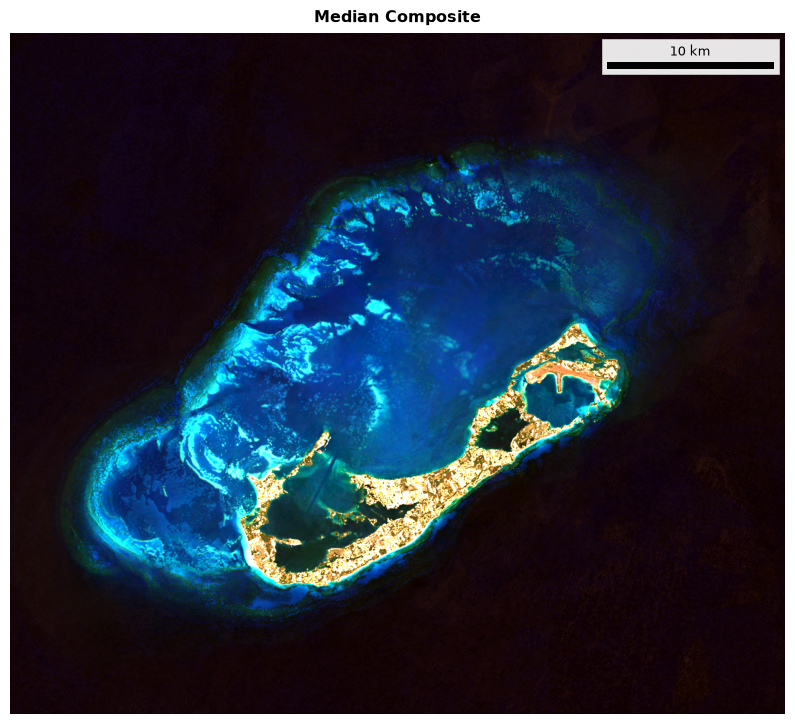

In [8]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    median_comp_img,
    img_bands=[4, 3, 2],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    no_data_val=-9999,
    title_str="Median Composite",
    show_scale_bar=True,
    show_map_axis=False,
)

## 5.1 Percentile Composites

The median is the 50th percentile. Other percentiles can also be useful, for example a low percentile (e.g., 25th) of the visible bands will tend to suppress any residual haze, thin cloud or sun glint which brighten the water. `calc_img_band_pxl_percentiles` calculates per-pixel percentiles across the images for each band; the output has one band per input band and percentile (here 7 bands named `b1_p25` ... `b7_p25`).

(`rsgispy.imagecalc.percentiles.calc_imgs_pxl_percentiles` is a different function: it stacks *all* the bands of *all* the images together, which is useful for single-band time series but not for a multi-band composite.)

`rsgispy.imageutils.composite.create_percentile_composite`, used in section 8, also calculates per-band percentiles, with a choice of band and which observations are valid (see below).

In [9]:
p25_comp_img = os.path.join(out_dir, "bermuda_p25_landsat_comp.tif")
rsgispy.imagecalc.percentiles.calc_img_band_pxl_percentiles(
    input_imgs,
    p25_comp_img,
    percentiles=[25],
    gdalformat="GTIFF",
    no_data_val=-9999,
)
print(rsgispy.imageutils.metadata.get_band_names(p25_comp_img))

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

['b1_p25', 'b2_p25', 'b3_p25', 'b4_p25', 'b5_p25', 'b6_p25', 'b7_p25']


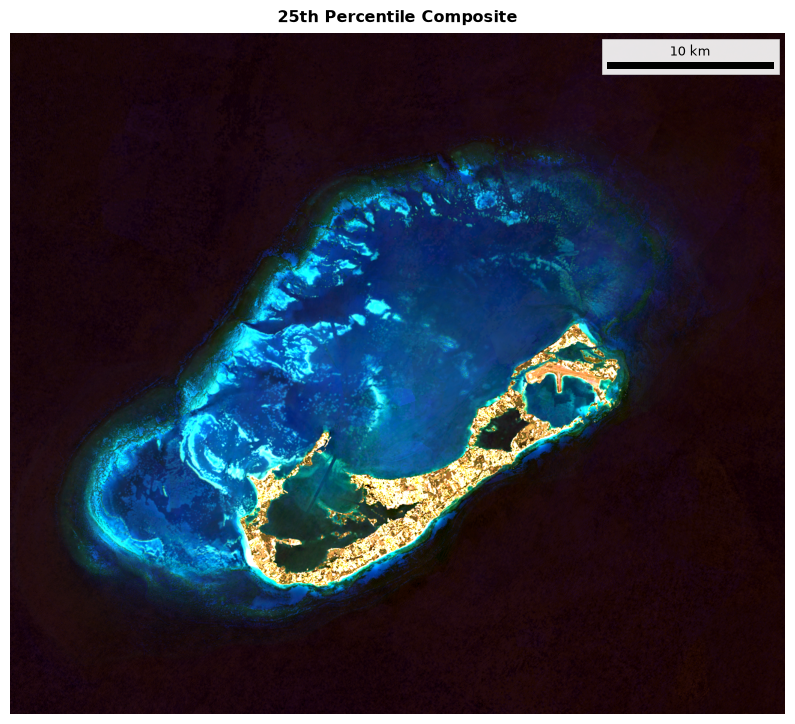

In [10]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    p25_comp_img,
    img_bands=[4, 3, 2],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    no_data_val=-9999,
    title_str="25th Percentile Composite",
    show_scale_bar=True,
    show_map_axis=False,
)

# 6. Create Minimum or Maximum Composites

Probably not appropriate in this case but just to illustrate you can use the same function to create minimum and maximum reflectance composites.

In [11]:
min_comp_img = os.path.join(out_dir, "bermuda_min_landsat_comp.tif")
rsgispy.imagecalc.stats.calc_multi_img_band_stats(
    input_imgs,
    min_comp_img,
    rsgispy.SUMTYPE_MIN,
    use_no_data=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32INT,
    no_data_val=-9999,
)
# Set the no data value on the output and calculate the statistics and pyramids
rsgispy.imageutils.metadata.set_img_no_data_value(min_comp_img, -9999)
rsgispy.imageutils.stats.pop_img_stats(min_comp_img, no_data_val=-9999, calc_pyramids=True)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

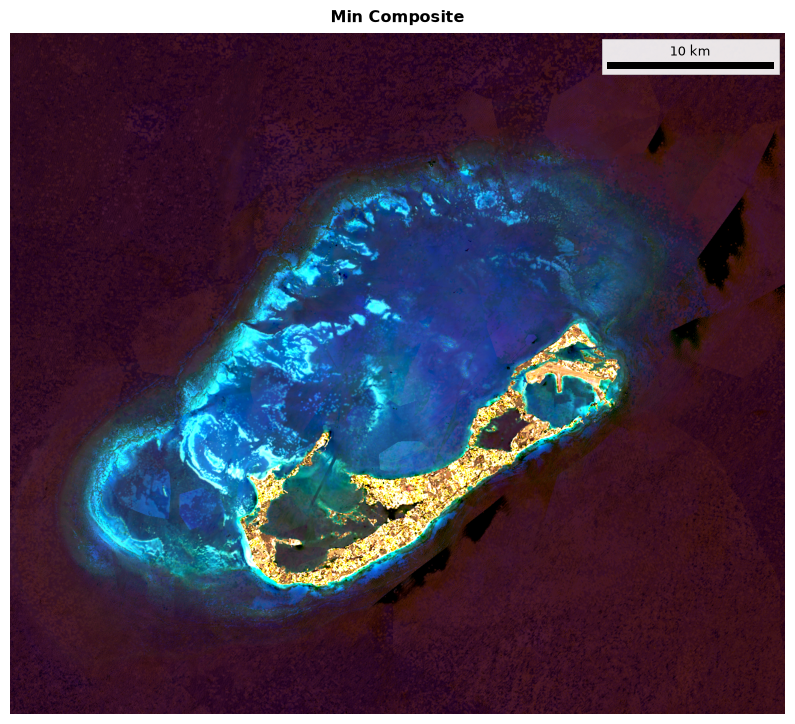

In [12]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    min_comp_img,
    img_bands=[4, 3, 2],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    no_data_val=-9999,
    title_str="Min Composite",
    show_scale_bar=True,
    show_map_axis=False,
)

In [13]:
max_comp_img = os.path.join(out_dir, "bermuda_max_landsat_comp.tif")
rsgispy.imagecalc.stats.calc_multi_img_band_stats(
    input_imgs,
    max_comp_img,
    rsgispy.SUMTYPE_MAX,
    use_no_data=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32INT,
    no_data_val=-9999,
)
# Set the no data value on the output and calculate the statistics and pyramids
rsgispy.imageutils.metadata.set_img_no_data_value(max_comp_img, -9999)
rsgispy.imageutils.stats.pop_img_stats(max_comp_img, no_data_val=-9999, calc_pyramids=True)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

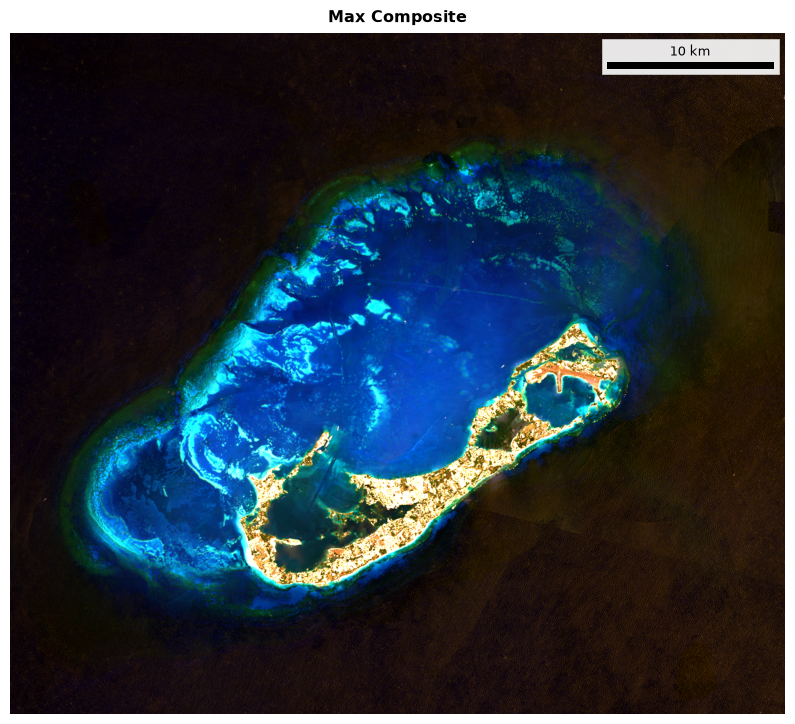

In [14]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))
_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    max_comp_img,
    img_bands=[4, 3, 2],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    no_data_val=-9999,
    title_str="Max Composite",
    show_scale_bar=True,
    show_map_axis=False,
)

# 7. Create a Max. NDVI / Medoid Composite

All the composites above treat each band separately, so an output pixel can combine, for example, the blue value of one date with the green value of another. An alternative is a "best pixel" composite where, for each pixel, one observation (date) is selected using a rule and all its bands are copied to the output. The output pixel values are then real measured reflectances.

The rule used here first creates a land/water mask and then:

 * over **land** it selects the observation with the maximum NDVI (the greenest, least cloudy observation), i.e., a maximum NDVI composite;
 * over **water** it selects the *medoid* observation (Flood 2013): the observation with the smallest sum of distances (over all the bands) to the other valid observations of that pixel. Like the median composite this is robust to outliers (residual cloud, cloud shadow, sun glint), but the output pixel is a real observation. Selecting the extreme of an index (e.g., the minimum NIR) over water tends to pick cloud shadows, which are also dark in the NIR.

Flood, N. (2013). Seasonal composite Landsat TM/ETM+ images using the medoid (a multi-dimensional median). Remote Sensing, 5(12), 6481-6500.

`create_max_ndvi_ndwi_composite` does this. By default it uses the RSGISLib land/water rule (NDVI > 0.3 is land, otherwise NDWI > 0.01 is water) and the maximum NDWI over water. On these Landsat scenes the water reflectances are close to zero (and often slightly negative), which makes those ratios unstable, so we give our own rule and method:

 * `water_rule="b5 <= 500 ? 1 : 0"`: each observation votes water where the NIR (band 5) is at most 500 (5 % reflectance) and land otherwise;
 * `min_water_frac=0.501`: a pixel is water when more than half its valid observations vote water (the majority, or mode, of the votes);
 * `water_method="medoid"`: the medoid is used over water rather than the maximum NDWI.

Once this has run you will want to check the classification of water versus land as errors in that layer will affect the quality of the resulting composite.

This produces 3 output images:

 1. The output composite image.
 2. The mask separating land (1) and water (2).
 3. A reference image from which you can identify which input image (1-11, in the order listed in section 2) the output pixel value was taken from.

> **RSGISLib users:** this is the equivalent of `imageutils.imagecomp.create_max_ndvi_ndwi_composite` (with `swir_band` and no `water_rule`, rsgispy uses RSGISLib's NDWI and land/water rule). Unlike RSGISLib, the images must already be on the same pixel grid (RSGISLib subset them to the extent of a reference image). `create_land_water_composite` is the general form, with any land and water quality, and `create_max_ndvi_composite` is a max. NDVI composite without the water rule.

> **Note:** earlier versions of this tutorial wrote this composite with NumPy, selecting the water observation nearest the per-band median of bands 1-4. That is not quite a medoid (which uses the distances between the observations themselves, here over all 7 bands), so about half of the water pixels now come from a different observation; the land/water mask and the land pixels are unchanged.

In [15]:
# Landsat 8/9 OLI bands: 1 = coastal, 2 = blue, 3 = green, 4 = red, 5 = NIR
max_ndvi_ndwi_val_comp_img = os.path.join(out_dir, "bermuda_max_ndvi_ndwi_landsat_comp.tif")
max_ndvi_ndwi_val_comp_wl_msk = os.path.join(
    out_dir, "bermuda_max_ndvi_ndwi_landsat_water_land_msk.tif"
)
max_ndvi_ndwi_val_comp_ref_img = os.path.join(
    out_dir, "bermuda_max_ndvi_ndwi_landsat_comp_ref.tif"
)

rsgispy.imageutils.composite.create_max_ndvi_ndwi_composite(
    input_imgs,
    max_ndvi_ndwi_val_comp_img,
    red_band=4,
    nir_band=5,
    green_band=3,
    water_rule="b5 <= 500 ? 1 : 0",
    min_water_frac=0.501,
    water_method="medoid",
    no_data_val=-9999,
    out_lw_msk_img=max_ndvi_ndwi_val_comp_wl_msk,
    out_ref_img=max_ndvi_ndwi_val_comp_ref_img,
    gdalformat="GTIFF",
    use_pbar=False,
)

The land/water mask and the reference image are thematic images with a colour table and class names (the land/water mask's are "Land" and "Water"; the reference image's are the input file names). The file names are long for a legend, so we rename the reference classes with the acquisition dates, using `set_thematic_classes`, which sets the class names, the colour table and the thematic statistics in one call. We also give the classes more distinct colours (matplotlib's `tab10` colours plus black).

> **RSGISLib users:** `set_thematic_classes` replaces the `rastergis.pop_rat_img_stats` + `rastergis.set_class_names` + colour table sequence.

In [16]:
ref_clrs = [matplotlib.colors.to_hex(c) for c in matplotlib.colormaps["tab10"].colors] + ["#000000"]
ref_names = {}
for img_idx, input_img in enumerate(input_imgs, start=1):
    # The acquisition date is the 4th part of the file name (e.g. 20150122)
    acq_date = os.path.basename(input_img).split("_")[3]
    ref_names[img_idx] = (
        f"{img_idx}: {acq_date[:4]}-{acq_date[4:6]}-{acq_date[6:]}",
        ref_clrs[img_idx - 1],
    )
rsgispy.imageutils.colourtable.set_thematic_classes(max_ndvi_ndwi_val_comp_ref_img, ref_names)

# The number of pixels selected from each input image
ref_arr = rsgispy.imageutils.arrays.get_img_data_as_arr(max_ndvi_ndwi_val_comp_ref_img, [1])
n_pxls = numpy.bincount(ref_arr.ravel(), minlength=len(input_imgs) + 1)
for img_idx, (name, clr) in ref_names.items():
    print(f"{name}: {n_pxls[img_idx]} pixels")

1: 2015-01-22: 110720 pixels
2: 2018-06-23: 3039 pixels
3: 2017-04-17: 401635 pixels
4: 2017-08-07: 749208 pixels
5: 2018-05-22: 12243 pixels
6: 2019-08-29: 219923 pixels
7: 2021-03-11: 108151 pixels
8: 2021-06-15: 1209 pixels
9: 2021-08-02: 229090 pixels
10: 2021-10-21: 15058 pixels
11: 2022-01-01: 249192 pixels


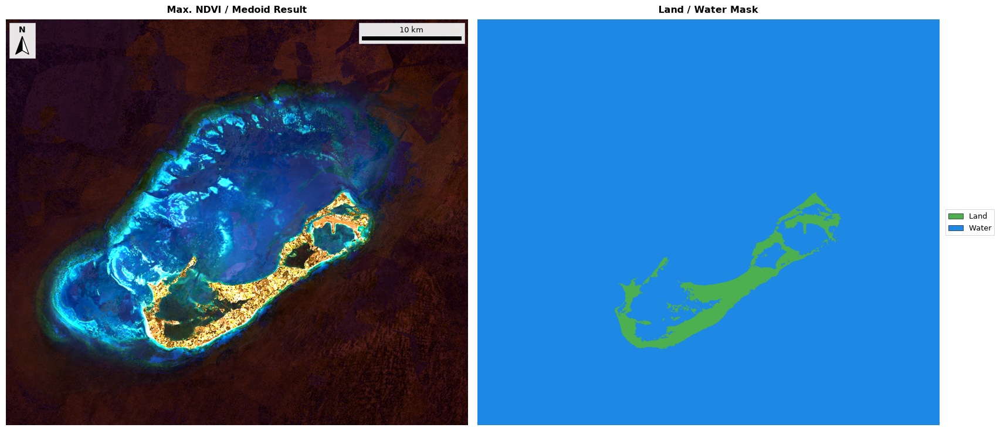

In [17]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb",
            max_ndvi_ndwi_val_comp_img,
            bands=[4, 3, 2],
            title="Max. NDVI / Medoid Result",
            map_kw={"no_data_val": -9999},
        ),
        map_layout.MapPanel("thematic", max_ndvi_ndwi_val_comp_wl_msk, title="Land / Water Mask"),
    ],
    figsize=(16, 7.5),
)

The reference image is mapped in section 8.4, next to the reference image of another composite. (It is not drawn in the same figure as the land/water mask because `create_map_panels` draws one legend for all the thematic panels, keyed by pixel value, and both images use the values 1 and 2.)

# 8. Geomedian, Median and Quality Mosaic Composites

## 8.1 Geomedian Composite

A **geometric median** (geomedian) composite (Roberts, Mueller and McIntyre 2017) is, for each pixel, the multi-band point which minimises the sum of the (Euclidean) distances to all the valid observations. It is the multi-dimensional equivalent of the median: like the medoid it is robust to outliers (residual cloud and shadow) and keeps the relationship between the bands (unlike a per-band median), but it is not restricted to one of the observations, so it is less noisy than a medoid or best-pixel composite and has no seams between dates. The downside is that the output values are not measured reflectances. It is calculated iteratively (Weiszfeld's algorithm), so it is slower than the other composites (about 30 seconds here).

Roberts, D., Mueller, N. and McIntyre, A. (2017). High-dimensional pixel composites from Earth observation time series. IEEE Transactions on Geoscience and Remote Sensing, 55(11), 6254-6264.

`create_geomedian_composite` can also output the number of valid observations (`out_count_img`), the observation nearest the geomedian (`out_ref_img`) and the median absolute deviations from the geomedian (`out_mad_img`), which are useful for change detection.

In [18]:
geomedian_comp_img = os.path.join(out_dir, "bermuda_geomedian_landsat_comp.tif")
geomedian_count_img = os.path.join(out_dir, "bermuda_geomedian_landsat_count.tif")
rsgispy.imageutils.composite.create_geomedian_composite(
    input_imgs,
    geomedian_comp_img,
    no_data_val=-9999,
    out_count_img=geomedian_count_img,
    gdalformat="GTIFF",
    use_pbar=False,
)

## 8.2 Median Composite

`create_percentile_composite` creates a per-band median (or other percentile) composite. It is similar to the median composite in section 5, but by default (`valid_rule="all_bands"`) an observation is only used at a pixel if all its bands are valid, so each band of a pixel is the median of the same set of observations. The output is 32-bit float (the median of an even number of values is a mean of two).

In [19]:
median_pc_comp_img = os.path.join(out_dir, "bermuda_median_pc_landsat_comp.tif")
rsgispy.imageutils.composite.create_percentile_composite(
    input_imgs,
    median_pc_comp_img,
    percentiles=[50],
    no_data_val=-9999,
    gdalformat="GTIFF",
    use_pbar=False,
)
print(rsgispy.imageutils.metadata.get_band_names(median_pc_comp_img))

['b1_p50', 'b2_p50', 'b3_p50', 'b4_p50', 'b5_p50', 'b6_p50', 'b7_p50']


## 8.3 Quality Mosaic: Minimum Blue

The max. NDVI composite is one example of a *quality mosaic*: each pixel takes the whole observation with the largest (or smallest) value of a quality band or expression (like Google Earth Engine's `qualityMosaic`). `create_quality_mosaic` creates one with any quality: a band number, a band maths expression (e.g. `"(b5 - b4) / (b5 + b4)"`) or a Python function. Here we use the minimum of the blue band (band 2), a simple filter of haze, thin cloud and sun glint, which all brighten the blue.

In [20]:
min_blue_comp_img = os.path.join(out_dir, "bermuda_min_blue_landsat_comp.tif")
min_blue_comp_ref_img = os.path.join(out_dir, "bermuda_min_blue_landsat_comp_ref.tif")
rsgispy.imageutils.composite.create_quality_mosaic(
    input_imgs,
    min_blue_comp_img,
    quality=2,
    mode="min",
    no_data_val=-9999,
    out_ref_img=min_blue_comp_ref_img,
    gdalformat="GTIFF",
    use_pbar=False,
)
rsgispy.imageutils.colourtable.set_thematic_classes(min_blue_comp_ref_img, ref_names)

## 8.4 Compare the Composites

`create_map_panels` draws the composites side by side with the same extent, so they are easy to compare. Each composite is stretched separately (cumulative stretch).

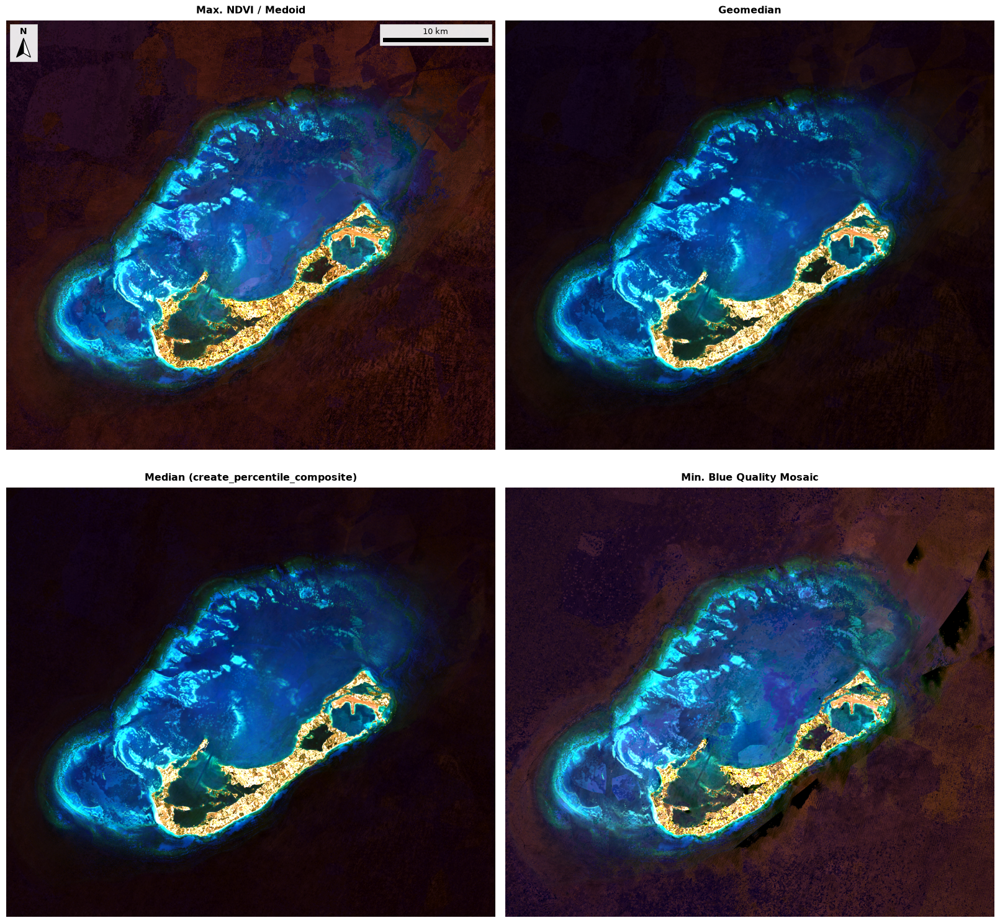

In [21]:
comp_imgs = {
    "Max. NDVI / Medoid": max_ndvi_ndwi_val_comp_img,
    "Geomedian": geomedian_comp_img,
    "Median (create_percentile_composite)": median_pc_comp_img,
    "Min. Blue Quality Mosaic": min_blue_comp_img,
}
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", img, bands=[4, 3, 2], title=title, map_kw={"no_data_val": -9999}
        )
        for title, img in comp_imgs.items()
    ],
    ncols=2,
    figsize=(16, 15),
)

The geomedian and median composites are the smoothest, with no seams between dates. The two best-pixel composites show some seams where neighbouring pixels come from different dates. The minimum blue composite also has some dark patches on the right of the image: these are cloud shadows (and dark cloud edges) which were not masked and, being dark in the blue, are selected by the rule. This is the same problem as selecting the minimum NIR over water, and why a robust rule (e.g. the medoid, or `mode="percentile"`) is often better than an extreme.

The reference images show which input image each pixel of the two best-pixel composites came from. The max. NDVI / medoid composite draws on all the images, while the minimum blue composite takes large areas of water from only a few dates.

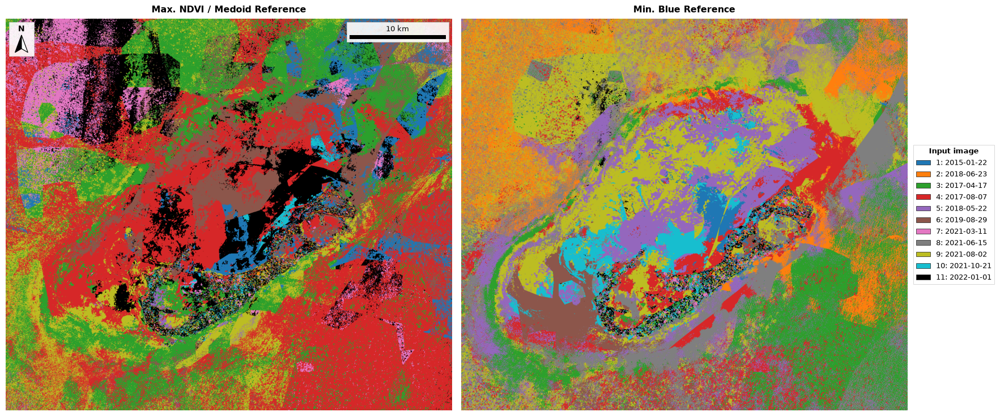

In [22]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("thematic", max_ndvi_ndwi_val_comp_ref_img, title="Max. NDVI / Medoid Reference"),
        map_layout.MapPanel("thematic", min_blue_comp_ref_img, title="Min. Blue Reference"),
    ],
    legend_title="Input image",
    figsize=(16, 8),
)

# 9. Conclusions

In this case the input imagery is pretty tidy so it looks like all the methods have provided quite a good output. However, the minimum and maximum composites have some clear artifacts so those should be rejected in preference of one of the others. The geomedian is the smoothest of the composites (no seams between dates), while the best-pixel composites (max. NDVI / medoid and minimum blue) keep measured reflectances. It is suggested that you would probably want to open these composites in TuiView or QGIS and compare them in more detail.

For the next notebook we will use the max. NDVI / medoid composite as that treats image pixels as single units rather than bands separately and will therefore have pixel values which are measured reflectances rather than derived (i.e., mean, median or geomedian).